# 02 NH투자증권(2018) 밸류 팩터 재현

## 0. 원문 정리
원문: NH투자증권 하재석·박소현(2018-07-16), 「Korea Factor Investing 시리즈(1): 밸류(Value) 팩터」. 시험 조건 상자(p.14), Multi-Metric(p.15), 그림 19(p.16), 현실적 밸류 투자(p.26).

| 항목 | 원문 | 쪽 | 우리 설정 |
|---|---|---|---|
| 유니버스 | KOSPI 상장종목 중 관리종목·거래정지 아닌 종목, 리밸런싱 당일 상장 종목(생존편향 제거) | 14 | `시장=["KS"]`, `("거래정지", {"아이템": CP10001650})`, `관리종목`(CP10001660) |
| 지표 | P/B(장부가), P/E(순이익), P/S(매출액), P/OCF(영업현금흐름), EV/EBITDA | 14 | `BP`·`EP`·`SP`·`CFP`·`EBITDA_EV` (역수 꼴, 높을수록 쌈) |
| 묶음 | 지표 기준 1~5분위, 동일가중 | 14 | `고르기=("분위",5)`, `비중=["동일"]` |
| 롱숏 | 1분위 Long − 5분위 Short. P/E·P/OCF는 적자 종목이 많아 1분위 − 4분위 | 14 | LS = Q1 − Q5 (P/E·P/OCF는 Q1 − Q4) |
| 리밸런싱 | 1개월 단위 월말 | 14 | `기준일="마지막거래일"`, `리밸런싱=1` |
| 재무 반영 | 분기/연간 재무제표가 발표되는 월의 월말에 반영 | 14 | `재무시점=("발표일",150)`: 실적보고서발표일(FP56000900) 다음 거래일부터, 발표일이 없으면 결산일 + 150일(확인판 180일). 150·180일은 근거 없음(아래 발표 지연 통계는 늦은 발표 비율만 보여 줌). **연간만**(분기 없음) |
| 기간 | 2002-03 ~ 2018-05 | 14 | 원문 기간 = `("2002-03","2018-05")` |
| Multi-Metric | 5개 지표 Z-Score 합산 순위로 고른 1분위 Long Only 동일가중 | 15 | `합산="z합산"`, Q1 |
| 위험조정수익률(그림 19) | 월간 변동성 대비 절대수익률: Multi 0.39, P/B 0.34, P/E 0.32, EV/EBITDA 0.34, P/S 0.30, P/OCF 0.29 | 16 | Q1 월평균 수익률 / 월 표준편차 |
| 현실판 | KOSPI 시총 300위 이내, 월평균 거래대금 10억 원 이상, Multi-Metric, 매매비용 월 0.2%, 벤치마크 KOSPI 200 동일가중지수 | 26 | `("시총상위",{"n":300})`, `("거래대금", {"창": "월"})`(기준일이 든 달의 거래일 평균), `거래비용=dict(..., 월비용=0.002)`(본 결과), 비용 없는 판 함께. **기간은 원문 그림 36('09.1~'18)대로 2009-01 말 첫 리밸런싱 ~ 2018-05**(끝 달은 원문에 없어 본 실험 끝을 씀). 2002-03부터 판은 '확장' 줄 |

줄임말: EW(동일가중, Equal Weight), VW(시가총액가중, Value Weight), LS(롱숏: 좋은 분위를 사고 나쁜 분위를 판 수익률),
MDD(최대 낙폭, Maximum Drawdown), IR(정보비율, Information Ratio), CAPM(자본자산가격결정모형), FF3(파마-프렌치 3요인), Carhart(카하트 4요인: FF3 + 모멘텀),
OLS(보통최소제곱), NW(뉴이-웨스트: 자기상관·이분산을 감안한 t), TR(배당 포함 수정주가).

## 1. 불러오기
계산은 모두 `공통/` 폴더의 모듈이 한다. 이 노트북은 설정을 정하고, 실행하고, 결과를 본다.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "공통"))
import numpy as np
import pandas as pd
import 데이터읽기 as 읽기, 종목거르기, 지표, 포트폴리오 as 포, 평가
pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

## 2. 데이터 경로와 기간
데이터를 어디서 읽을지, 어느 기간을 돌릴지 정한다. 기간은 (첫 리밸런싱 월, 마지막 기준일 월)이다.

In [2]:
# 새로 통째로 받은 파일(읽기.DATA 기본 = data\통합_전체_202611, DataGuide 달력기준 일간)로 원문 기간을 돌린다.
기간 = ("2002-03", "2018-05")
print("데이터:", 읽기.DATA, "/ 기간:", 기간)

데이터: D:\26-2_데이터기반투자전략\과제02\data\통합_전체_202611 / 기간: ('2002-03', '2018-05')


## 3. 설정
지표만 바꿔 같은 설정으로 돌린다. 원문 본 실험 조건(p.14)에는 거래비용 언급이 없어 0으로 둔다(원문이 비용을 뺐는지는 알 수 없음).

In [3]:
기본 = {**포.기본설정, "이름": "NH밸류", "시장": ["KS"], "기간": 기간, "기준일": "마지막거래일", "리밸런싱": 1,
       "재무시점": ("발표일", 150), "제외": [("거래정지", {"아이템": 읽기.정지여부}), "관리종목"],
       "고르기": ("분위", 5), "비중": ["동일"], "거래비용": dict(수수료=0, 거래세=0, 슬리피지=0)}
지표명 = {"P/B": "BP", "P/E": "EP", "P/S": "SP", "P/OCF": "CFP", "EV/EBITDA": "EBITDA_EV"}
숏 = {"P/E": "Q4", "P/OCF": "Q4"}  # 원문: 적자 종목이 많아 1분위 − 4분위
pd.Series(기본).astype(str).to_frame("공통 설정")

,공통 설정
시장,['KS']
가격,S410007700
기간,"('2002-03', '2018-05')"
기준일,마지막거래일
리밸런싱,1
재무시점,"('발표일', 150)"
제외,"[('거래정지', {'아이템': 'CP10001650'}), '관리종목']"
지표,"[('ROC', '높게'), ('EY', '높게')]"
합산,순위합산
고르기,"('분위', 5)"


### 재무시점 근거: 결산일 → 실적보고서발표일 일수 (12월 결산 연간)
`포.발표지연()`이 연간재무 전체(새 일간 재무에서 뽑은 전 종목·전 회계연도, 자산총계가 있는 행)에서 다시 계산한다. 발표일이 결산일보다 뒤인 행만 센다.
- 표 **'결산월 이력'**: 회계연도별 결산월(CP10002200)이 12인 행. 백테스트가 결산일을 잡는 방식과 같다.

규칙: 발표일이 있으면 발표일 다음 거래일부터 쓴다. 발표일이 없으면 본문은 결산일 + 150일, 확인판은 결산일 + 180일로 한다. **150·180일은 위 표에서 바로 나온 값이 아니다(근거 없음)**: 99% 칸은 전체 112일, 2000년 이후 104~125일이다(1995~99년만 443.66일). 표가 보여 주는 것은 발표일이 그보다 늦은 비율이다('150일 초과' 전체 0.007, '180일 초과' 0.006). 발표일이 없는 행에 150일을 쓸 때 미래 정보가 생길 수 있는 정도를 보여 준다. 법정기한 90일은 쓰지 않는다. '90일 초과' 칸만큼 실제 발표가 그보다 늦어서 미래 정보가 생기기 때문이다.
예전 통계(분기·연간, 법정기한 대비)는 `data\DataGuide_추가_202610\_deadline_stats_log.txt`에 있다.
- 예전에 함께 보이던 '정적 결산월' 표는 지금 없다. 새로 받은 파일에는 정적 결산월 키 열이 없기 때문이다(예전 합친 연간재무에만 있었음).

In [4]:
포.발표지연("CP10002200").style.set_caption("결산월 이력 = 12").format(precision=3)

,행,발표일 있음,건수,중앙값(일),95%(일),99%(일),90일 초과,150일 초과,180일 초과
1987~94,5541.000,0.000,0.000,nan,nan,nan,nan,nan,nan
1995~99,6055.000,0.086,523.000,90.000,97.900,443.660,0.069,0.015,0.015
2000~04,9587.000,0.705,6761.000,89.000,99.000,106.000,0.148,0.005,0.004
2005~10,13382.000,0.893,11951.000,76.000,98.000,104.000,0.121,0.003,0.002
2011~26,39473.000,0.918,36238.000,77.000,97.000,125.260,0.101,0.008,0.008
전체,74038.000,0.749,55473.000,78.000,98.000,112.000,0.110,0.007,0.006


## 4. 실행: 지표별 5분위 + Multi-Metric

In [5]:
결과 = {n: 포.실행({**기본, "지표": [(m, "높게")]}) for n, m in 지표명.items()}
결과["Multi-Metric"] = 포.실행({**기본, "지표": [(m, "높게") for m in 지표명.values()], "합산": "z합산"})
F = 평가.요인(포.기준일(기본), 기본)
pd.DataFrame({n: (1 + o["수익률"]["동일"]).prod() - 1 for n, o in 결과.items()}).T.rename_axis("누적수익률")

,Q1,Q2,Q3,Q4,Q5
누적수익률,,,,,
P/B,49.6433,20.7413,11.9033,2.8023,0.7448
P/E,28.7889,11.6008,5.9939,4.7726,5.2294
P/S,34.1080,16.8806,13.6961,3.5820,1.3435
P/OCF,37.5915,14.5143,6.8229,2.6048,4.7910
EV/EBITDA,19.2801,11.8598,14.8210,6.0278,2.3761
Multi-Metric,49.2762,18.7980,8.5077,4.9028,0.7549


## 5. 롱숏(LS) 성과와 그림

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
P/B,194.0000,24.2466,0.2211,0.1458,1.4517,-0.2219,0.5427,0.0176,5.8368,5.4502,0.0178,5.8848,5.4692,0.0081,3.1713,2.8948,0.0097,3.9306,4.0485,-0.0445,0.2080,0.8095,-0.2254,0.4295
P/E,194.0000,3.8767,0.1030,0.1060,0.9810,-0.2354,0.1162,0.0087,3.9446,3.5875,0.0086,3.8964,3.6540,0.0031,1.5077,1.3079,0.0042,2.0529,1.9624,0.0135,0.0117,0.4532,-0.1473,0.2562
P/S,194.0000,14.7015,0.1857,0.1466,1.2423,-0.2929,0.5229,0.0152,4.9951,4.4889,0.0141,4.8861,4.4750,0.0063,2.4695,2.2481,0.0077,3.0709,2.8690,0.2605,0.3213,0.6568,-0.1918,0.4216
P/OCF,194.0000,9.6132,0.1573,0.0983,1.5429,-0.1570,0.3629,0.0126,6.2037,6.1640,0.0124,6.0851,6.1909,0.0071,3.7319,3.8626,0.0077,4.0326,4.6265,0.0677,0.0544,0.4341,-0.0828,0.2627
EV/EBITDA,194.0000,3.4176,0.0962,0.1387,0.7333,-0.3099,0.0870,0.0085,2.9483,2.7308,0.0092,3.2774,3.1807,0.0049,1.8149,1.7535,0.0042,1.5478,1.4842,-0.1818,-0.2196,0.3210,0.0931,0.2298


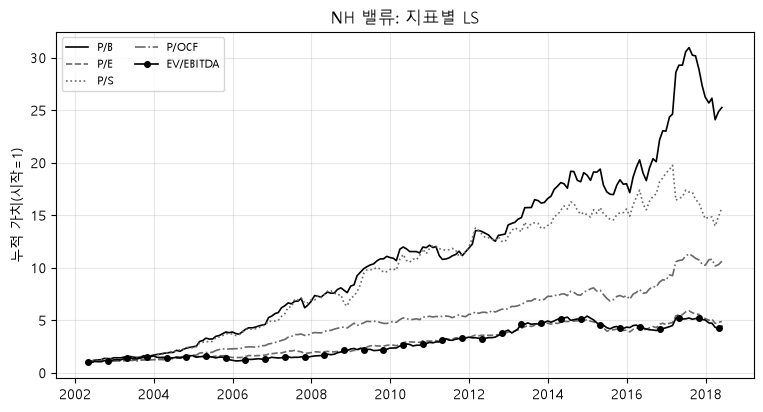

In [6]:
LS = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"][숏.get(n, "Q5")] for n, o in 결과.items() if n != "Multi-Metric"})
평가.누적그림(LS, "NH 밸류: 지표별 LS");
평가.성과표(LS, F, list(LS))

## 6. 1분위 Long Only 성과 (그림 18·19)

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
P/B,194.0000,49.6433,0.2748,0.2355,1.0302,-0.4930,1.2927,0.0202,4.1420,3.4373,0.0162,5.2058,4.7562,0.0091,4.5034,4.1625,0.0098,4.7787,4.2979,1.0039,0.7630,0.5927,-0.0845,0.8516
P/E,194.0000,28.7889,0.2336,0.2340,0.8924,-0.5220,1.1923,0.0174,3.5882,3.0254,0.0132,4.7296,4.3714,0.0072,3.9177,3.9186,0.0073,3.9218,3.7149,1.0561,0.6911,0.4938,-0.0162,0.8741
P/S,194.0000,34.1080,0.2462,0.2498,0.8931,-0.5191,1.1772,0.0186,3.5908,3.0416,0.0142,4.6230,4.3052,0.0082,4.3759,3.9429,0.0088,4.6540,4.0101,1.1124,0.8002,0.5017,-0.0785,0.8871
P/OCF,194.0000,37.5915,0.2535,0.2323,0.9663,-0.4668,1.3639,0.0187,3.8852,3.2770,0.0145,5.4050,5.1246,0.0087,4.9205,5.0294,0.0088,4.8842,4.5984,1.0637,0.6624,0.4748,-0.0098,0.8821
EV/EBITDA,194.0000,19.2801,0.2046,0.2045,0.8708,-0.4582,1.0391,0.0149,3.5015,2.9910,0.0112,4.4209,4.1594,0.0061,3.3166,3.2145,0.0062,3.3520,3.1308,0.9031,0.5906,0.4276,-0.0215,0.8370
Multi-Metric,194.0000,49.2762,0.2742,0.2385,1.0173,-0.5078,1.3223,0.0202,4.0903,3.4106,0.0161,5.2762,4.8550,0.0089,4.5914,4.2747,0.0093,4.7220,4.0722,1.0386,0.7556,0.5951,-0.0498,0.8662
KOSPI,194.0000,1.7055,0.0635,0.1867,0.2642,-0.4852,NaN,0.0041,1.0622,0.9656,-0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,NaN,NaN,1.0000,-0.0000,-0.0000,0.0000,1.0000


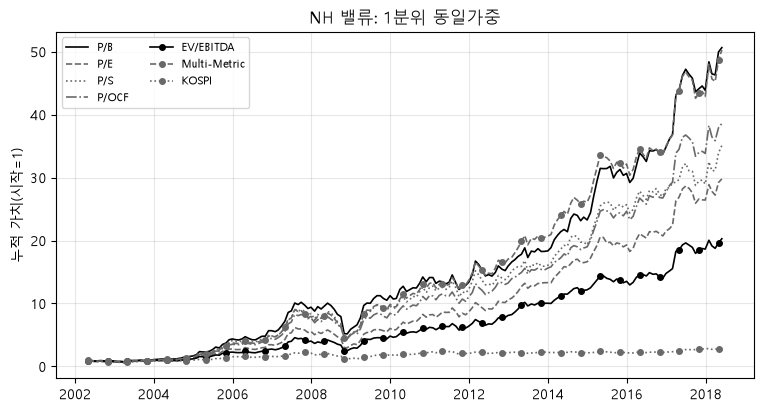

In [7]:
Q1 = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] for n, o in 결과.items()})
Q1["KOSPI"] = F["시장"]
평가.누적그림(Q1.dropna(how="all"), "NH 밸류: 1분위 동일가중");
평가.성과표(Q1.dropna(how="all"), F)

## 7. 현실판(p.26): 시총 300위 이내 + 거래대금 10억 원 이상, Multi-Metric, 매매비용 월 0.2%
원문(p.26): "이러한 방식으로 매월 전체 포트폴리오의 0.2% 매매비용을 감안해 1개월 단위 리밸런싱한 결과 KOSPI 200 동일가중지수를 Outperform할 수 있었다(그림36 참조)."
그림 36 제목(p.26): "5가지 지표 Multi-Metric 방식으로 선정한 동일가중 포트폴리오 수익률 (1개월 단위 리밸런싱, 매매비용 월 0.2% 가정)".
본 결과는 매달 포트폴리오의 0.2%를 뺀 판이고, 비용 없는 판을 옆에 둔다. 벤치마크는 원문대로 KOSPI 200 동일가중지수(X01 `I.401` '코스피 200 동일가중지수', 종가지수, 값은 2009-01-02부터)를 놓는다(2026-11-04 고침, 예전엔 '데이터에 없음'으로 잘못 보고 코스피 I.001). 배당 포함 여부는 X01에 적혀 있지 않다(확인 안 함). 코스피(I.001)는 참고로 함께 둔다.

In [8]:
# 원문 p.26 그림 36 가로축 '09.1~'18 → 2009-01 말 첫 리밸런싱(끝 달은 원문에 없어 본 실험 끝 2018-05를 씀). 유니버스: 시총 300위·월평균 거래대금 10억
현실설정 = {**기본, "이름": "NH밸류_현실판", "기간": ("2009-01", 기간[1]), "지표": [(m, "높게") for m in 지표명.values()], "합산": "z합산",
           "제외": 기본["제외"] + [("시총상위", {"n": 300}), ("거래대금", {"창": "월"})]}
월비용 = dict(수수료=0, 거래세=0, 슬리피지=0, 월비용=0.002)
현실 = {"현실판_비용월0.2%(본)": 포.실행({**현실설정, "거래비용": 월비용}),
        "현실판_비용없음": 포.실행(현실설정),
        "확장: 현실판_2002-03부터_비용월0.2%": 포.실행({**현실설정, "기간": 기간, "거래비용": 월비용})}
F200 = 평가.요인(포.기준일(기본), {**기본, "시장지수": "I.401"})  # 원문 벤치마크(p.26). 정보비율·CAPM α가 이 지수 기준
현실표 = pd.DataFrame({k: o["수익률"][("동일", "Q1")] for k, o in 현실.items()} | {"KOSPI200 동일가중(I.401)": F200["시장"], "KOSPI(I.001, 참고)": F["시장"]})
평가.성과표(현실표.loc["2009-02":], F200.loc["2009-02":])  # I.401 첫 값 2009-01-02 → 첫 수익률 달 = 2009-02 말

,개월,누적,연환산,표준편차(연),샤프,MDD,정보비율,초과평균 α(월),초과평균 t(OLS),초과평균 t(NW),CAPM α(월),CAPM t(OLS),CAPM t(NW),FF3 α(월),FF3 t(OLS),FF3 t(NW),Carhart α(월),Carhart t(OLS),Carhart t(NW),Carhart β:MKT,Carhart β:SMB,Carhart β:HML,Carhart β:MOM,Carhart adj R²
현실판_비용월0.2%(본),194.0000,8.2395,0.1474,0.2542,0.5533,-0.4935,0.7367,0.0117,2.2248,2.0823,0.0068,2.7541,2.9771,0.0027,1.1562,1.1766,0.0037,1.6377,1.5880,1.2160,0.3363,0.3539,-0.1473,0.8403
현실판_비용없음,194.0000,12.6246,0.1753,0.2547,0.6479,-0.4781,0.9306,0.0138,2.6050,2.4382,0.0088,3.5699,3.8588,0.0047,2.0264,2.0621,0.0058,2.5137,2.4373,1.2184,0.3370,0.3546,-0.1476,0.8403
KOSPI,194.0000,1.7055,0.0635,0.1867,0.2642,-0.4852,NaN,0.0041,1.0622,0.9656,-0.0000,NaN,NaN,0.0000,NaN,NaN,0.0000,NaN,NaN,1.0000,-0.0000,-0.0000,0.0000,1.0000


## 8. 원문 vs 우리
원문은 대부분 그림이라 숫자는 그림 19(위험조정수익률)만 비교한다. 나머지는 원문의 문장(주장)과 우리 결과가 같은 방향인지 본다.

In [9]:
그림19 = pd.Series({"Multi-Metric": 0.39, "P/B": 0.34, "P/E": 0.32, "EV/EBITDA": 0.34, "P/S": 0.30, "P/OCF": 0.29})
우리19 = (Q1.mean() / Q1.std())[그림19.index]
그림19표 = pd.DataFrame({"원문 그림19": 그림19, "우리(Q1 월평균/월표준편차)": 우리19})
display(그림19표)
누적LS = (1 + LS).prod() - 1
주장 = pd.DataFrame({"원문 주장": ["모든 지표에서 LS 누적이 양(+)", "P/B·P/E가 가장 효과적(LS 누적 상위 2)", "Multi-Metric 1분위가 단일 지표 1분위보다 위험조정수익률 높음"],
              "우리": [bool((누적LS > 0).all()), sorted(누적LS.nlargest(2).index) == ["P/B", "P/E"], bool(우리19.idxmax() == "Multi-Metric")]})
그림19표.to_csv(평가.결과폴더 / "02_원문대조_그림19.csv", encoding="utf-8-sig")  # 결과요약 노트북이 읽음
주장.to_csv(평가.결과폴더 / "02_원문주장.csv", encoding="utf-8-sig")
주장

,원문 그림19,우리(Q1 월평균/월표준편차)
Multi-Metric,0.3900,0.3302
P/B,0.3400,0.3343
P/E,0.3200,0.2949
EV/EBITDA,0.3400,0.2940
P/S,0.3000,0.2926
P/OCF,0.2900,0.3164


,원문 주장,우리
0,모든 지표에서 LS 누적이 양(+),True
1,P/B·P/E가 가장 효과적(LS 누적 상위 2),False
2,Multi-Metric 1분위가 단일 지표 1분위보다 위험조정수익률 높음,False


## 9. 확인판: 재무시점 180일, 무위험이자율
- **재무시점**: 발표일이 없는 행에 결산일 + 150일 대신 180일을 쓰면 LS 누적이 달라지는지 본다.
- **무위험이자율**: 본문은 콜금리(1일물 중개거래, E11.02.003.001). 1988년부터 빈 달 없이 값이 있는 금리는 이것과 무담보콜금리(1일물 은행간 직거래, E11.02.003.002) 둘이다. 확인판은 무담보콜, 그리고 2000년 이후 기간은 통안채 364일(E11.02.003.009, 1993-07부터 있음. NH 원문 기간이 모두 2000년 이후라 전체 기간에 쓰임). 무위험이자율은 포트폴리오를 바꾸지 않고 샤프·알파만 바꾼다(1분위로 본다).

In [10]:
늦게 = {n: 포.실행({**기본, "지표": [(m, "높게")], "재무시점": ("발표일", 180)}) for n, m in 지표명.items()}
display(pd.DataFrame({"150일(본문)": (1 + LS).prod() - 1, "180일(확인판)": (1 + pd.DataFrame({n: o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"][숏.get(n, "Q5")] for n, o in 늦게.items()})).prod() - 1}).rename_axis("LS 누적"))
Q1x = pd.DataFrame({n: o["수익률"]["동일"]["Q1"] for n, o in 결과.items()}).dropna(how="all")
금리 = {"콜(본문)": F, "무담보콜": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.002"}),
       "통안364(2000년 이후)": 평가.요인(포.기준일(기본), {**기본, "무위험": "E11.02.003.009"}).loc["2000":]}
pd.concat({k: 평가.성과표(Q1x.loc[f.index[0]:], f)[["샤프", "CAPM α(월)", "Carhart α(월)"]] for k, f in 금리.items()}, axis=1)

,150일(본문),180일(확인판)
LS 누적,,
P/B,24.2466,23.4321
P/E,3.8767,3.7636
P/S,14.7015,14.8087
P/OCF,9.6132,9.5112
EV/EBITDA,3.4176,3.2340


콜(본문)                          무담보콜                        통안364(2000년 이후)                       
                 샤프 CAPM α(월) Carhart α(월)     샤프 CAPM α(월) Carhart α(월)              샤프 CAPM α(월) Carhart α(월)
P/B          1.0302    0.0162       0.0098 1.0306    0.0162       0.0098          1.0126    0.0162       0.0098
P/E          0.8924    0.0132       0.0073 0.8929    0.0132       0.0073          0.8747    0.0132       0.0074
P/S          0.8931    0.0142       0.0088 0.8934    0.0142       0.0088          0.8766    0.0142       0.0088
P/OCF        0.9663    0.0145       0.0088 0.9667    0.0145       0.0088          0.9484    0.0145       0.0088
EV/EBITDA    0.8708    0.0112       0.0062 0.8714    0.0112       0.0062          0.8506    0.0112       0.0062
Multi-Metric 1.0173    0.0161       0.0093 1.0177    0.0161       0.0093          0.9999    0.0161       0.0093

## 10. 확인: 리밸런싱마다 종목 수·빈칸으로 빠진 수

In [11]:
기록 = pd.concat({n: o["기록"] for n, o in 결과.items()}, axis=1)
display(기록.groupby(기록.index.year).mean().round(1).T)
기록.iloc[:3].T

기준일                            2002      2003      2004      2005      2006      2007      2008      2009      2010      2011      2012      2013      2014      2015      2016      2017      2018
P/B          가격있음         1686.4000 1733.2000 1740.8000 1751.2000 1819.9000 1893.2000 1961.8000 1957.7000 1948.1000 1963.1000 1952.9000 1919.4000 1923.0000 1979.4000 2064.2000 2123.2000 2162.0000
             시장            857.1000  854.7000  839.8000  844.2000  869.8000  891.9000  919.8000  920.0000  922.2000  929.2000  931.5000  916.1000  903.1000  884.5000  888.1000  884.0000  890.2000
             쓰지말것          856.8000  854.4000  838.6000  842.9000  868.8000  890.8000  918.2000  918.3000  920.2000  928.1000  930.1000  914.9000  902.4000  884.2000  888.1000  883.2000  890.2000
             거래정지          838.7000  838.9000  825.7000  826.6000  853.7000  877.0000  905.8000  908.0000  911.8000  918.5000  919.9000  904.1000  889.4000  872.8000  878.0000  873.6000  884.2000
             관리종목          743.9000  774.1000  776.5000  807.0000  847.9000  871.1000  896.9000  892.6000  899.5000  909.8000  908.9000  889.2000  871.7000  855.5000  868.0000  866.8000  879.2000
             빈칸:BP         168.2000  167.4000  162.8000  167.5000  173.8000  176.2000  183.3000  175.8000  167.9000  162.1000  153.1000  144.6000  132.3000  120.5000  122.0000  124.4000  128.0000
             보유수:동일:Q1     115.6000  121.7000  123.2000  128.2000  135.2000  139.2000  143.1000  143.8000  146.7000  149.9000  151.8000  149.2000  148.2000  147.3000  149.7000  148.8000  150.8000
             보유수:동일:Q2     115.0000  121.2000  122.6000  127.7000  134.7000  138.7000  142.5000  143.1000  146.2000  149.3000  150.8000  148.6000  147.6000  146.8000  149.0000  148.2000  150.0000
             보유수:동일:Q3     114.8000  121.2000  122.5000  127.8000  134.7000  139.1000  142.6000  143.3000  146.1000  149.3000  151.0000  148.9000  147.9000  146.9000  149.0000  148.4000  150.2000
             보유수:동일:Q4     115.0000  121.2000  122.6000  127.7000  134.7000  138.7000  142.5000  143.1000  146.2000  149.3000  150.8000  148.6000  147.6000  146.8000  149.0000  148.2000  150.0000
             보유수:동일:Q5     115.3000  121.5000  122.9000  128.2000  134.9000  139.2000  142.9000  143.6000  146.5000  149.8000  151.3000  149.2000  148.1000  147.2000  149.3000  148.8000  150.2000
             빈칸으로 빠짐       168.2000  167.4000  162.8000  167.5000  173.8000  176.2000  183.3000  175.8000  167.9000  162.1000  153.1000  144.6000  132.3000  120.5000  122.0000  124.4000  128.0000
             편입:Q1         115.6000  121.7000  123.2000  128.2000  135.2000  139.2000  143.1000  143.8000  146.7000  149.9000  151.8000  149.2000  148.2000  147.3000  149.7000  148.8000  150.8000
             편입:Q2         115.0000  121.2000  122.6000  127.7000  134.7000  138.7000  142.5000  143.1000  146.2000  149.3000  150.8000  148.6000  147.6000  146.8000  149.0000  148.2000  150.0000
             편입:Q3         114.8000  121.2000  122.5000  127.8000  134.7000  139.1000  142.6000  143.3000  146.1000  149.3000  151.0000  148.9000  147.9000  146.9000  149.0000  148.4000  150.2000
             편입:Q4         115.0000  121.2000  122.6000  127.7000  134.7000  138.7000  142.5000  143.1000  146.2000  149.3000  150.8000  148.6000  147.6000  146.8000  149.0000  148.2000  150.0000
             편입:Q5         115.3000  121.5000  122.9000  128.2000  134.9000  139.2000  142.9000  143.6000  146.5000  149.8000  151.3000  149.2000  148.1000  147.2000  149.3000  148.8000  150.2000
             확인:업종빈칸         9.4000   10.0000    6.9000    7.6000    9.9000   13.4000   25.2000   26.8000   26.0000   28.1000   26.1000   26.1000   24.3000   23.5000   23.3000   23.2000   23.0000
             확인:WICS금융      58.1000   60.0000   60.2000   79.7000   99.5000  108.3000  108.4000  103.2000  104.1000   97.7000   65.8000   61.1000   59.2000   55.6000   57.2000   57.8000   57.0000
P/E          가격있음         1686.4000 1733.2000 1740.8000 1751.2000 1819.9000 1893

기준일                        2002-03-29  2002-04-30  2002-05-31
P/B          가격있음                1670        1646        1660
             시장                   876         847         849
             쓰지말것                 876         847         849
             거래정지                 836         822         834
             관리종목                 720         726         733
             빈칸:BP                165         165         164
             보유수:동일:Q1            111         113         114
             보유수:동일:Q2            111         112         114
             보유수:동일:Q3            111         112         113
             보유수:동일:Q4            111         112         114
             보유수:동일:Q5            111         112         114
             빈칸으로 빠짐              165         165         164
             편입:Q1                111         113         114
             편입:Q2                111         112         114
             편입:Q3                111         112         113
             편입:Q4                111         112         114
             편입:Q5                111         112         114
             확인:업종빈칸                9           9           9
             확인:WICS금융             55          56          57
P/E          가격있음                1670        1646        1660
             시장                   876         847         849
             쓰지말것                 876         847         849
             거래정지                 836         822         834
             관리종목                 720         726         733
             빈칸:EP                165         165         164
             보유수:동일:Q1            111         113         114
             보유수:동일:Q2            111         112         114
             보유수:동일:Q3            111         112         113
             보유수:동일:Q4            111         112         114
             보유수:동일:Q5            111         112         114
             빈칸으로 빠짐              165         165         164
             편입:Q1                111         113         114
             편입:Q2                111         112         114
             편입:Q3                111         112         113
             편입:Q4                111         112         114
             편입:Q5                111         112         114
             확인:업종빈칸                9           9           9
             확인:WICS금융             55          56          57
P/S          가격있음                1670        1646        1660
             시장                   876         847         849
             쓰지말것                 876         847         849
             거래정지                 836         822         834
             관리종목                 720         726         733
             빈칸:SP                166         166         165
             보유수:동일:Q1            111         112         114
             보유수:동일:Q2            111         112         113
             보유수:동일:Q3            110         112         114
             보유수:동일:Q4            111         112         113
             보유수:동일:Q5            111         112         114
             빈칸으로 빠짐              166         166         165
             편입:Q1                111         112         114
             편입:Q2                111         112         113
             편입:Q3                110         112         114
             편입:Q4                111         112         113
             편입:Q5                111         112         114
             확인:업종빈칸                9           9           9
             확인:WICS금융             55          56          57
P/OCF        가격있음                1670        1646        1660
             시장                   876         847         849
             쓰지말것                 876         847         849
             거래정지                 836         822         834
             관리종목                 720         726         733
             빈칸:CFP               165         165         164
             보유수:동일:Q1          

## 11. 차이 이유 후보
- **재무 주기**: 원문은 분기·연간 재무를 발표 월말에 반영한다. 받은 재무는 결산(연간) 항목뿐이라 분기 갱신이 빠진다.
- **지표 방향**: 원문은 P/B 등 배수 그대로 줄 세웠을 것이다. 우리는 역수(B/P 등)로 줄 세워 적자·자본잠식 종목이 '싼 쪽'에 섞이지 않는다. 원문이 P/E·P/OCF를 Q1−Q4로 한 것은 적자 종목이 Q5에 모이는 것과 같은 효과로 보인다.
- **Z-Score**: 원문의 극단값 처리(윈저라이즈 등)가 나와 있지 않다. 우리는 처리하지 않는다. 5개 지표가 모두 있는 종목만 쓴다.
- **EV·EBITDA 정의**: 원문에 정의가 없다. 우리는 EV = 시가총액 + 부채총계 − 현금, EBITDA = DataGuide M000701032.
- **벤치마크**: 시장지수는 코스피 가격지수(I.001, 배당 미포함)인데 포트폴리오는 배당 포함 수정주가(TR)다. 정보비율·CAPM α가 배당수익률만큼 높게 나온다(코스피 TR I.030은 X01에 있지만 원문 벤치마크가 아니라 쓰지 않음). KOSPI 행의 알파·t는 자기 자신 회귀라 뜻이 없다.

## 12. 원문과 다르게 한 것
| 항목 | 원문 | 우리 | 이유 |
|---|---|---|---|
| 재무 | 분기+연간, 발표 월말 | 연간만, 실적보고서발표일 다음 거래일(없으면 결산일 + 150일, 확인판 180일) | 받은 재무가 결산(연간) 항목뿐. 150·180일은 근거 없음(3절 표의 99% 칸은 104~125일, '150일 초과'는 0.7%) |
| 지표 꼴 | P/B, P/E 등 | 역수 B/P, E/P 등 | 음수 분모가 싼 쪽에 줄 서는 것 막기 |
| 관리·정지 | 관리종목·거래정지 아닌 종목 | 그날 CP10001660(관리종목여부)·CP10001650(거래정지여부) 값 | 두 자료 모두 일간 |
| 상장 구간 | 상장 종목 | 시장구분(CP10000300)이 코스피·코스닥('KS'·'KQ')인 날의 가격만 계산에 씀(`읽기.상장가격`). 원본 값은 그대로 | 통합_확인기록 F2(상장일보다 앞선 가격 = 이전상장 전 시장 가격)·F3(상장폐지 뒤 장외 가격). 회원 결정 2026-11-02 |
| '쓰지 말 것' 칸 | — | 리밸런싱일이 README_데이터의 '쓰지 말 것' 구간 (시작, 끝]에 드는 종목은 편입 대상에서 뺌(`종목거르기.쓰지말것`, 항상 `시장` 다음 단계). 보유 중 걸린 칸은 TR 이상칸이면 그 구간 수정주가 수익률, 나머지는 빈칸(`포.쓰지말것칸`, 2026-11-04 고침: 전에는 다음 리밸런싱일까지 보고 뺌 = 미래 정보). 직전 12개월 일간수익률에서도 빈칸으로 봄. 값은 그대로 | A008080 2004-01~2013-09(D-05, 재조회 R28도 값 같음), 수정주가 병합·감자 미반영 7칸의 그 달(D27), 배당 포함 가격(TR)을 쓸 때 TR 이상칸의 앞날~그날(D-06·U3. 2026-11-04 같은 규칙으로 새 데이터에서 다시 만든 232칸, `_검증/새목록/`). 회원 결정 2026-11-02 |
| 호텔신라(A008770) FY2023 | — | 매출원가·매출총이익을 빈칸으로 봄 → 그해 GP/A 등에서 제외(값은 그대로, `지표.빈칸으로볼칸`) | 판본마다 값이 다름(R29 재조회는 매출원가 0, 10월 파일은 1,418,625,926천원). 통합_확인기록 F1. 회원 결정 2026-11-02 |
| 끝 날짜 | — | 가격·시장 일간 항목(S·CP 파일)에 값이 있는 마지막 날(`읽기.공통끝`)에서 자름. 재무 일간은 끝나지 않은 회계연도가 빈칸이라 판정에서 뺌 | 통합_확인기록 F6(항목마다 끝 날짜가 다를 수 있음) |
| 코드 재사용 16종목 | — | 재사용 경계를 넘는 수익률을 쓰지 않음(공백 구간이 빈칸이라 끊김, 01 노트북 11절에서 확인). 직전 12개월 상장 판정도 시장구분으로 함 | 통합_확인기록 F5, README_데이터 D-04 |
| 재무 값 뽑기 | — | 달력기준 일간 재무에서 결산일(결산월 이력이 그 달인 달의 마지막 영업일) 값을 그 회계연도 값으로 씀(`읽기.연간재무`). 쓸 수 있는 날은 재무시점 규칙 | 일간 값은 발표 전부터 그 회계연도 값이 들어 있어 그대로 쓰면 미래 정보. 예전 연간 원본과 자산총계 79,657/79,837행 같음(`_검증/일간재무_대조_결과.txt`) |
| 같은 회계연도 두 결산월 | — | 결산일이 늦은 행 | 통합_확인기록 F9(A432320) |
| TR 이상칸 | — | 위 '쓰지 말 것' 칸 중 TR 이상칸이 이 노트북에 해당(배당 포함 가격을 씀) | README_데이터 D-06·U3 |
| 현실판 벤치마크 | KOSPI 200 동일가중지수 | 같음: X01 `I.401`(2026-11-04 고침. 예전엔 I.001) | 예전 '데이터에 없음'은 틀림(X01에 있음) |
| 현실판 기간 | 그림 36 가로축 '09.1~'18 | 2009-01 말 ~ 2018-05 (2026-11-04 원문대로 고침) | '09.1이 첫 리밸런싱인지 첫 수익률 달인지는 그림만으로 알 수 없음. 끝 달은 원문에 없어 본 실험 끝. 2002-03부터는 '확장' 줄 |
| 원문 주장 범위 | p.14~26에 결론 문장이 더 있음(그림 18 Multi-Metric 1분위 누적 '월등', 그림 17 2010년 이후 P/B·P/E, P/E 2015년 이후 부진, 1개월 리밸런싱 최고, 현실판 KOSPI 200 동일가중 대비 우위 등) | 원문주장 csv는 3개만 판정 | 0단계 대조(2026-11-04)에서 찾음. 진단 단계에서 판정 추가 |
| 현실판 거래대금 | 월평균 거래대금 | 기준일이 든 달의 거래일 평균 거래대금(S410000900, 원) | 2026-11-04 고침(전에는 20거래일, 근거 없음) |


## 14. 원문 차이 진단 (2026-11-04)
값을 원문에 맞추려고 고르지 않는다. 원인 후보마다 그 원인만 바꿔 돌린 숫자를 원문 숫자(그림 19, p.16)와 나란히 둔다. 판정 기준은 돌리기 전에 아래처럼 정했다.
- **'경계'**: 두 전략의 위험조정수익률(월평균/월표준편차) 차이를 Jobson·Korkie(1981) 식을 Memmel(2003)이 고친 식으로 검정해 p > 0.05이면, 순위가 '같음/다름'이 아니라 '경계'(순위를 가를 만큼 차이가 크지 않음). 누적·평균 차이는 두 월수익률 차이의 평균을 NW t로 검정(같은 기준). 두 논문 원문은 확인 안 함(식은 `평가.샤프차이` 설명).
- **옮기지 않은 원문 결론**(0단계 대조 28줄): 문장마다 판정 기준을 표에 같이 적는다. '월등'·'다소 부진'처럼 숫자 기준이 없는 말은 우리가 읽은 기준을 적는다.
- **원인 바꾸기**: (가) 재무 반영 180일, (나) 발표 당일부터 쓰기(원문 '발표 월의 월말'에 더 가까운 쪽: 발표일이 그 달 마지막 거래일이어도 그날 씀), (다) 지표를 원문처럼 배수 그대로(P/B 등 낮은 쪽이 1분위 → 적자·자본잠식 종목이 '싼 쪽'에 섞임). 분기 재무는 받지 않아(`_검증/추가로_받을것.md` 7절) 바꿔 볼 수 없다.

In [ ]:
# (1) '경계': Multi-Metric과 단일 지표 1분위의 위험조정수익률 차이(원문 주장 3), LS 누적 상위 2와 3위 차이(원문 주장 2)
q1 = Q1.drop(columns="KOSPI")
경계 = pd.DataFrame({f"Multi-Metric 대 {n}": 평가.샤프차이(q1["Multi-Metric"], q1[n]) for n in 지표명}).T
경계["판정"] = np.where(경계["p"] > 0.05, "경계", np.where(경계["차이"] > 0, "Multi가 높음", "Multi가 낮음"))
display(경계.style.set_caption("Multi-Metric 대 단일 지표 1분위: 월평균/월표준편차 차이 검정").format(precision=4))
순 = 누적LS.sort_values(ascending=False)
ls경계 = pd.DataFrame({f"{a} 대 {순.index[2]}": 평가.평균차이(LS[a], LS[순.index[2]]) for a in 순.index[:2]}).T
ls경계["판정"] = np.where(ls경계["p"] > 0.05, "경계", "차이 있음")
display(ls경계.style.set_caption(f"LS 누적 상위 2({', '.join(순.index[:2])}) 대 3위: 월 LS 차이 평균 검정").format(precision=4))

In [ ]:
# (2) 옮기지 않은 원문 결론 판정(원문 쪽·그림 번호, 판정 기준)
누적Q1 = (1 + q1).prod() - 1
최고단일 = 누적Q1.drop("Multi-Metric").idxmax()
월등 = 평가.평균차이(q1["Multi-Metric"], q1[최고단일])
ls10 = (1 + LS.loc["2010":]).prod() - 1
pe전, pe후 = [(1 + x).prod() ** (12 / len(x)) - 1 for x in (LS["P/E"].loc[:"2014"].dropna(), LS["P/E"].loc["2015":].dropna())]
주기 = {k: 포.실행({**기본, "지표": [("BP", "높게")], "리밸런싱": k}) for k in (1, 3, 6, 12)}
주기LS = pd.DataFrame({f"{k}개월": o["수익률"]["동일"]["Q1"] - o["수익률"]["동일"]["Q5"] for k, o in 주기.items()})
주기누적 = (1 + 주기LS).prod() - 1
본현실 = 현실표["현실판_비용월0.2%(본)"].loc["2009-02":].dropna()
벤치 = F200["시장"].reindex(본현실.index)
초과 = 평가.평균차이(본현실, 벤치)
판정 = lambda ok, p: "같음" if ok and p <= 0.05 else ("경계" if ok else "다름")
더주장 = pd.DataFrame([
    ["p.15 그림 18", "Multi-Metric 1분위 누적이 단일 지표 1분위보다 '월등하게 우수'", "Multi 누적이 단일 최고보다 크고, 월 차이 평균 p ≤ 0.05(크기만 크고 p > 0.05면 경계)",
     f"Multi {누적Q1['Multi-Metric']:.3f}, 단일 최고 {최고단일} {누적Q1[최고단일]:.3f}, p = {월등['p']:.3f}", 판정(누적Q1.idxmax() == "Multi-Metric", 월등["p"])],
    ["p.14 그림 17", "2010년 이후로 한정해도 P/B·P/E가 가장 효과적", "2010-01 말~ LS 누적 상위 2가 P/B·P/E",
     ", ".join(f"{k} {v:.3f}" for k, v in ls10.sort_values(ascending=False).items()), "같음" if set(ls10.nlargest(2).index) == {"P/B", "P/E"} else "다름"],
    ["p.14", "P/E는 2015년 이후 다소 부진", "(우리가 읽은 기준) P/E LS 연환산이 2015년 이후 < 2014년까지",
     f"~2014 {pe전:.4f}, 2015~ {pe후:.4f}", "같음" if pe후 < pe전 else "다름"],
    ["p.18 그림 23·24", "P/B LS는 1개월 리밸런싱이 가장 좋음(1·3·6·12개월 비교)", "LS 누적이 1개월에서 가장 큼",
     ", ".join(f"{k} {v:.3f}" for k, v in 주기누적.items()), "같음" if 주기누적.idxmax() == "1개월" else "다름"],
    ["p.26 그림 36", "현실판(비용 월 0.2%)이 KOSPI 200 동일가중지수를 Outperform", "같은 달 누적이 I.401보다 크고, 월 차이 평균 p ≤ 0.05(크기만 크면 경계)",
     f"현실판 {(1 + 본현실).prod() - 1:.3f}, I.401 {(1 + 벤치).prod() - 1:.3f}, p = {초과['p']:.3f}", 판정((1 + 본현실).prod() > (1 + 벤치).prod(), 초과["p"])],
    ["p.19~24", "애널리스트 추정 밸류·시총·유동성·코스닥 결론", "—", "안 함: 애널리스트 추정치는 받지 않음, 나머지는 원문 기본 실험 밖", "안 함"],
], columns=["원문 쪽·그림", "원문 결론", "판정 기준", "우리", "판정"])
더주장

In [ ]:
# (3) 원인 하나씩 바꾼 뒤 그림 19 숫자(Q1 월평균/월표준편차)와 LS 누적
for n, m in 지표명.items():  # 원문 꼴 '배수 그대로'(진단용): P/B = 1 / (B/P), 낮을수록 1분위
    setattr(지표, m + "_배수", lambda s, m=m: 1 / getattr(지표, m)(s))
def 판돌리기(d, 꼴):
    res = {n: 포.실행({**기본, **d, "지표": [(m + 꼴[0], 꼴[1])]}) for n, m in 지표명.items()}
    res["Multi-Metric"] = 포.실행({**기본, **d, "지표": [(m + 꼴[0], 꼴[1]) for m in 지표명.values()], "합산": "z합산"})
    return res
판 = {"기본(본문)": 결과, "재무 180일": 판돌리기(dict(재무시점=("발표일", 180)), ("", "높게")),
     "발표 당일부터": 판돌리기(dict(재무시점=("발표당일", 150)), ("", "높게")), "배수 그대로": 판돌리기({}, ("_배수", "낮게"))}
q = lambda o: o["수익률"]["동일"]["Q1"]
rows = {}
for k, res in 판.items():
    r19 = pd.Series({n: q(o).mean() / q(o).std() for n, o in res.items()})[그림19.index]
    ls = pd.Series({n: (1 + q(o) - o["수익률"]["동일"][숏.get(n, "Q5")]).prod() - 1 for n, o in res.items() if n != "Multi-Metric"})
    rows[k] = {("그림19", n): v for n, v in r19.items()} | {("LS 누적", n): v for n, v in ls.items()} | {
        ("요약", "그림19와 차이 절대값 평균"): (r19 - 그림19).abs().mean(), ("요약", "Multi가 1위"): r19.idxmax() == "Multi-Metric",
        ("요약", "LS 상위 2 = P/B·P/E"): set(ls.nlargest(2).index) == {"P/B", "P/E"}}
원인표 = pd.DataFrame(rows)
원인표["원문"] = pd.Series({("그림19", n): v for n, v in 그림19.items()})
원인표

### 원문 차이 진단 요약
| 원인 | 근거 | 바꾼 뒤 숫자 | 원문 | 남은 차이 |
|---|---|---|---|---|
| 재무 반영 늦춤(180일) | 원문 p.14 '발표 월의 월말'. 150·180일은 원문에 없음 | (3) 표 '재무 180일' 열 | 그림 19 6칸 | (3) 표 '그림19와 차이 절대값 평균' |
| 발표 당일부터 | 원문 p.14 '발표 월의 월말'(발표일이 그 달 안이면 그 달 말에 반영) | (3) 표 '발표 당일부터' 열 | 그림 19 6칸 | 같은 칸 |
| 지표 꼴(배수 그대로) | 원문 p.14 P/B·P/E 등 배수 이름. 정렬 꼴은 원문에 없음 | (3) 표 '배수 그대로' 열 | 그림 19 6칸 | 같은 칸 |
| 분기 재무 없음 | 원문 p.14 '분기/연간' | 바꿔 볼 수 없음(자료 없음) | — | 남음 |
| Multi 대 단일 지표 순위 | 원문 그림 19 Multi 0.39 > P/B 0.34 | (1) 표 p | — | p > 0.05면 '경계' |
| 현실판 벤치마크 | 원문 p.26 KOSPI 200 동일가중지수 | 본문을 I.401로 고침(7절), (2) 표 | Outperform | (2) 표 판정 |

숫자는 위 코드 출력이 정본이다. 본문(기본) 설정은 원문 문장이 받치는 것(현실판 벤치마크 I.401)만 바꾸고, (3)의 세 판은 진단으로만 둔다(재무 반영은 원문 문장을 우리 자료로 그대로 할 수 없고, 정렬 꼴은 원문에 없음).

## 13. 요약표용 저장
지표별 Q1, LS, 현실판의 월수익률을 `결과_월수익률/`에 남긴다(LS는 롱숏이라 초과수익 = 수익률 그대로).

In [12]:
S = pd.DataFrame({(f"NH밸류 {n} Q1", "동일"): Q1[n] for n in Q1 if n != "KOSPI"} | {(f"NH밸류 {n} LS", "동일"): LS[n] for n in LS}
                 | {(f"NH밸류 {k}", "동일"): o["수익률"][("동일", "Q1")] for k, o in 현실.items()})
평가.저장(S, F, "02_NH밸류", [k for k in S if k[0].endswith(" LS")])
list(S)

[('NH밸류 P/B Q1', '동일'),
 ('NH밸류 P/E Q1', '동일'),
 ('NH밸류 P/S Q1', '동일'),
 ('NH밸류 P/OCF Q1', '동일'),
 ('NH밸류 EV/EBITDA Q1', '동일'),
 ('NH밸류 Multi-Metric Q1', '동일'),
 ('NH밸류 P/B LS', '동일'),
 ('NH밸류 P/E LS', '동일'),
 ('NH밸류 P/S LS', '동일'),
 ('NH밸류 P/OCF LS', '동일'),
 ('NH밸류 EV/EBITDA LS', '동일'),
 ('NH밸류 현실판_비용월0.2%(본)', '동일'),
 ('NH밸류 현실판_비용없음', '동일')]